In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_DIR = Path().cwd().parent / 'data'
data = pd.read_csv(DATA_DIR / 'train.csv')

In [8]:
data.head()

,Unnamed: 0,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [9]:
data.duplicated().sum()

np.int64(0)

In [27]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 82 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     1460 non-null   int64  
 1   Id             1460 non-null   int64  
 2   MSSubClass     1460 non-null   int64  
 3   MSZoning       1460 non-null   str    
 4   LotFrontage    1201 non-null   float64
 5   LotArea        1460 non-null   int64  
 6   Street         1460 non-null   str    
 7   Alley          91 non-null     str    
 8   LotShape       1460 non-null   str    
 9   LandContour    1460 non-null   str    
 10  Utilities      1460 non-null   str    
 11  LotConfig      1460 non-null   str    
 12  LandSlope      1460 non-null   str    
 13  Neighborhood   1460 non-null   str    
 14  Condition1     1460 non-null   str    
 15  Condition2     1460 non-null   str    
 16  BldgType       1460 non-null   str    
 17  HouseStyle     1460 non-null   str    
 18  OverallQual    1460

In [30]:
y = data['SalePrice']
X = data.drop(columns=['SalePrice'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

CATERGORICAL_COLUMNS = [col for col in X_train.columns if ((X_train[col].dtype == 'object') | (X_train[col].dtype == 'str'))]
NUMERICAL_COLUMNS = [col for col in X_train.columns if ((X_train[col].dtype != 'str') & (X_train[col].dtype != 'object'))].remove('Id')

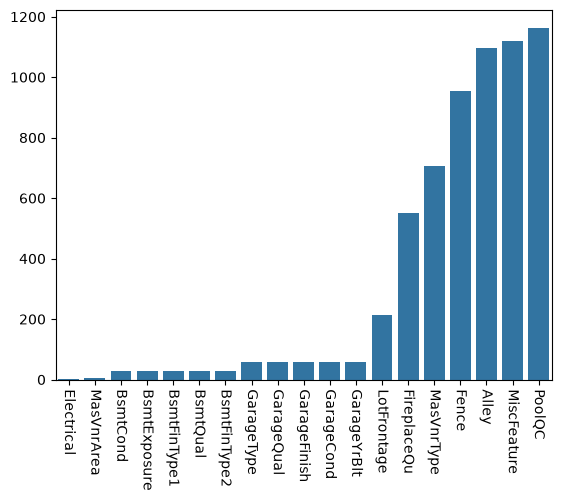

In [33]:
missing = X_train.isna().sum()
missing = (missing[missing > 0]).sort_values()
sns.barplot(missing)
plt.xticks(rotation=-90)
plt.show()